# Práctica 4 — Punto 2: K-Vecinos más Cercanos (KNN)

**Reconocimiento de patrones**

Este notebook desarrolla, en el mismo orden de la guía, la implementación de `KNNClasificador` y los experimentos sobre el dataset **Wine**:

1. Implementación de KNN con distancia Minkowski.
2. Efecto del número de vecinos `k`.
3. Efecto de la normalización Z-score.
4. Efecto del exponente `p` de Minkowski.
5. Preguntas de análisis.

> Ejecuta las celdas de arriba hacia abajo. El notebook usa `random_state=42` para que el experimento sea reproducible.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns', 50)

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## 2.1. Implementación de `KNNClasificador`

La clase no aprende parámetros durante `fit`: únicamente almacena los datos de entrenamiento. Al predecir, calcula las distancias Minkowski, selecciona los `k` vecinos más cercanos y devuelve la clase más votada.

**Desempate elegido:** si dos o más clases empatan en votos, se escoge la clase con la etiqueta numérica menor. Es un criterio determinista y fácil de reproducir.

In [ ]:
class KNNClasificador:
    """KNN multiclase con distancia Minkowski parametrizable."""

    def fit(self, X_train, y_train):
        # KNN no ajusta parámetros: conserva los datos de entrenamiento.
        self.X_train = np.asarray(X_train, dtype=float)
        self.y_train = np.asarray(y_train)

        if self.X_train.ndim != 2:
            raise ValueError('X_train debe ser una matriz de dos dimensiones.')
        if len(self.X_train) != len(self.y_train):
            raise ValueError('X_train y y_train deben tener el mismo número de filas.')
        return self

    def predict(self, X_test, k, p=2):
        X_test = np.asarray(X_test, dtype=float)

        if not hasattr(self, 'X_train'):
            raise RuntimeError('Primero debes llamar a fit(X_train, y_train).')
        if not isinstance(k, (int, np.integer)) or k < 1 or k > len(self.X_train):
            raise ValueError(f'k debe ser un entero entre 1 y {len(self.X_train)}.')
        if p < 1:
            raise ValueError('El exponente p de Minkowski debe ser mayor o igual a 1.')
        if X_test.ndim == 1:
            X_test = X_test.reshape(1, -1)
        if X_test.shape[1] != self.X_train.shape[1]:
            raise ValueError('X_test debe tener el mismo número de características que X_train.')

        predicciones = []
        for x in X_test:
            # Distancia Minkowski: (sum(|xi - yi|^p))^(1/p)
            distancias = np.sum(np.abs(self.X_train - x) ** p, axis=1) ** (1.0 / p)

            # Seleccionar los k vecinos más cercanos.
            indices = np.argpartition(distancias, k - 1)[:k]
            etiquetas, votos = np.unique(self.y_train[indices], return_counts=True)

            # np.unique entrega las etiquetas ordenadas; argmax resuelve empates
            # eligiendo la menor etiqueta numérica.
            clase_ganadora = etiquetas[np.argmax(votos)]
            predicciones.append(clase_ganadora)

        return np.asarray(predicciones)

print('Clase KNNClasificador implementada.')

Clase KNNClasificador implementada.


## Preparación del dataset Wine

Se divide el dataset en 80 % entrenamiento y 20 % prueba usando `random_state=42`. Se conserva una copia de los datos originales y se calcula Z-score con la media y la desviación estándar del conjunto de entrenamiento únicamente; después se aplica esa transformación a entrenamiento y prueba.

In [ ]:
wine = load_wine()
X = wine.data
y = wine.target
nombres_clases = wine.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Z-score: el escalador se ajusta SOLO con entrenamiento.
escalador = StandardScaler()
X_train_norm = escalador.fit_transform(X_train)
X_test_norm = escalador.transform(X_test)

print(f'Muestras totales: {len(X)}')
print(f'Muestras de entrenamiento: {len(X_train)} ({len(X_train)/len(X):.0%})')
print(f'Muestras de prueba: {len(X_test)} ({len(X_test)/len(X):.0%})')
print(f'Características: {X.shape[1]}')
print('Clases:', list(nombres_clases))

Muestras totales: 178
Muestras de entrenamiento: 142 (80%)
Muestras de prueba: 36 (20%)
Características: 13
Clases: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


## 2.2. Experimento 1 — Efecto del número de vecinos `k`

Se usan datos normalizados, distancia euclidiana (`p=2`) y más de 10 valores de `k`, desde vecinos muy cercanos hasta valores mayores. Para la exactitud de entrenamiento se predicen las mismas muestras usadas para ajustar/almacenar KNN; por tanto, con `k=1` cada muestra se cuenta como su propio vecino. Esto es la medición directa solicitada por la práctica.

,k,Exactitud entrenamiento,Exactitud prueba
0,1,1.000,0.944
1,3,0.958,0.944
2,9,0.979,0.944
3,15,0.979,0.972
4,30,0.979,0.972
5,41,0.972,1.000
6,61,0.965,0.972
7,81,0.951,1.000
8,101,0.697,0.778
9,121,0.401,0.417


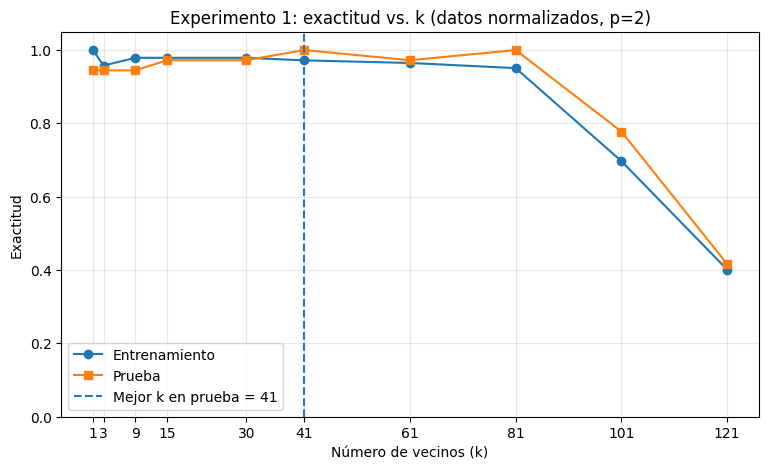

Mejor k del experimento 1: 41; exactitud de prueba = 1.000.


In [ ]:
k_values = [1, 3, 9, 15, 30 ,41, 61, 81, 101, 121 ]
knn_norm = KNNClasificador().fit(X_train_norm, y_train)
resultados_k = []

for k in k_values:
    pred_train = knn_norm.predict(X_train_norm, k=k, p=2)
    pred_test = knn_norm.predict(X_test_norm, k=k, p=2)
    resultados_k.append({
        'k': k,
        'Exactitud entrenamiento': accuracy_score(y_train, pred_train),
        'Exactitud prueba': accuracy_score(y_test, pred_test)
    })

df_k = pd.DataFrame(resultados_k)
display(df_k.style.format({'Exactitud entrenamiento': '{:.3f}', 'Exactitud prueba': '{:.3f}'}))

# Si hay empate en exactitud de prueba, se toma el primer k de la lista (el menor).
indice_mejor_k = int(np.argmax(df_k['Exactitud prueba'].to_numpy()))
k_mejor_exp1 = int(df_k.iloc[indice_mejor_k]['k'])
exactitud_mejor_exp1 = float(df_k.iloc[indice_mejor_k]['Exactitud prueba'])

plt.figure(figsize=(9, 5))
plt.plot(df_k['k'], df_k['Exactitud entrenamiento'], marker='o', label='Entrenamiento')
plt.plot(df_k['k'], df_k['Exactitud prueba'], marker='s', label='Prueba')
plt.axvline(k_mejor_exp1, linestyle='--', label=f'Mejor k en prueba = {k_mejor_exp1}')
plt.xlabel('Número de vecinos (k)')
plt.ylabel('Exactitud')
plt.title('Experimento 1: exactitud vs. k (datos normalizados, p=2)')
plt.xticks(k_values)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f'Mejor k del experimento 1: {k_mejor_exp1}; exactitud de prueba = {exactitud_mejor_exp1:.3f}.')


### Análisis del experimento 1: efecto del número de vecinos k

El experimento permite analizar cómo cambia la exactitud del clasificador KNN al modificar el número de vecinos k, manteniendo los datos normalizados con Z-score y la distancia euclidiana (p = 2).

De acuerdo con la gráfica, el mejor resultado en el conjunto de prueba se obtuvo con **k = 41 y k = 81**, alcanzando una exactitud del **100 %** en ambos casos. Sin embargo, con k = 41 se obtuvo una exactitud de entrenamiento aproximada del 97.18 %, mientras que con k = 81 la exactitud de entrenamiento fue aproximadamente del 95 %. Por tanto, k = 41 se mantiene como una buena elección, aunque k = 81 también alcanza el máximo de prueba.

**¿En qué rango de k presenta sobreajuste?**

Los indicios de sobreajuste aparecen principalmente con valores pequeños de k, especialmente k = 1, donde la exactitud de entrenamiento alcanza el 100 %, frente al 94.44 % de prueba. Esta diferencia de 5.56 puntos porcentuales indica que el resultado sobre los datos conocidos es mejor que sobre los datos nuevos. También se observan diferencias menores en otros valores pequeños de k. No obstante, no se aprecia un sobreajuste grave y sostenido en todo ese rango. Además, con k = 1 cada muestra de entrenamiento puede ser su propio vecino más cercano, lo que favorece artificialmente la exactitud de entrenamiento.

**¿En qué rango de k hay subajuste?**

El subajuste se observa claramente con valores grandes, especialmente k = 101 y k = 121. En k = 101, la exactitud de entrenamiento cae aproximadamente al 70 % y la de prueba al 77.78 %. En k = 121, ambas disminuyen hasta aproximadamente el 40 % y el 41.67 %, respectivamente.

Este comportamiento indica que, al considerar demasiados vecinos, el modelo pierde capacidad para distinguir correctamente las clases. Al participar una gran proporción de las muestras de entrenamiento en cada votación, las predicciones se vuelven demasiado generales. Por tanto, en esta gráfica se identifica evidencia de subajuste en la zona de k grandes, especialmente entre k = 101 y k = 121.

**¿Las dos curvas convergen conforme k crece?**

Las curvas no convergen de manera gradual durante todo el experimento. Sin embargo, con valores grandes de k se aproximan después de que ambas exactitudes disminuyen considerablemente. Por ejemplo, con k = 121, la exactitud de entrenamiento es aproximadamente del 40 % y la de prueba del 41.67 %.

Esto representa una convergencia numérica de ambas curvas, pero no un buen desempeño del modelo: las dos se aproximan a valores bajos. Por ello, es importante distinguir entre que las curvas estén próximas y que el clasificador generalice correctamente.

**Conclusión:** en esta partición del dataset Wine, k = 41 y k = 81 obtienen la máxima exactitud de prueba, del 100 %. Los valores pequeños muestran algunos indicios de sobreajuste, particularmente k = 1, mientras que los valores grandes, especialmente k = 101 y k = 121, presentan un claro deterioro de ambas exactitudes, consistente con el subajuste. Las curvas se aproximan con k grande, pero lo hacen después de perder capacidad predictiva.



## 2.3. Experimento 2 — Efecto de la normalización

Se repite la evaluación con los mismos valores de `k` y `p=2`, en dos condiciones: **sin normalizar** y **normalizando con Z-score**. El escalador para la condición normalizada ya fue ajustado únicamente con `X_train`.

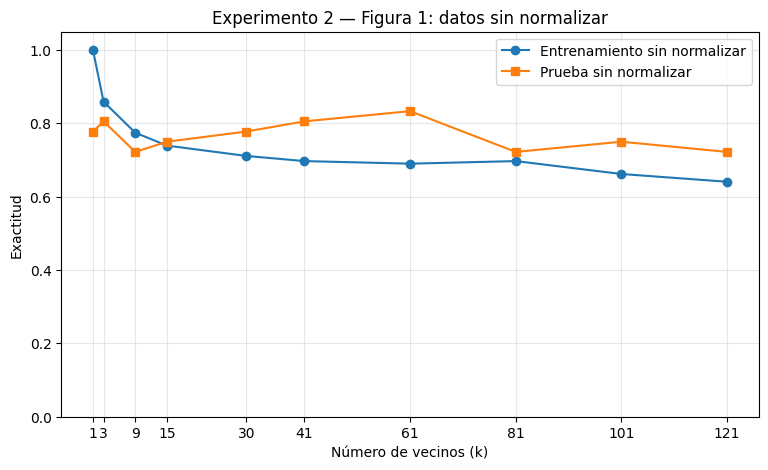

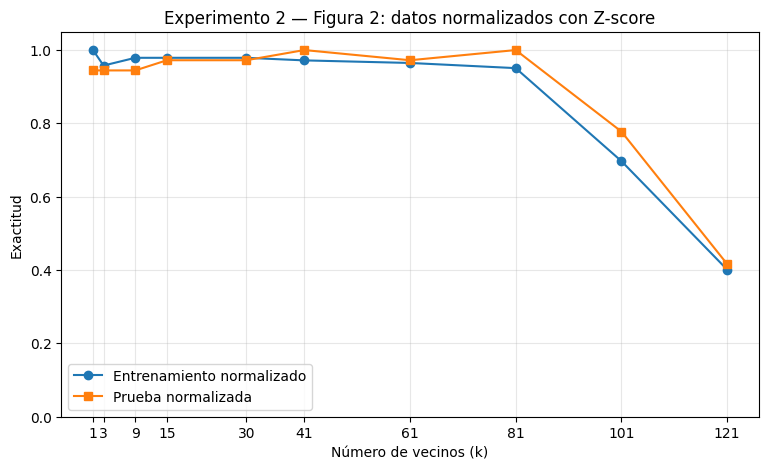

Comparación de métricas para cada valor de k:


,k,Entrenamiento sin normalizar,Prueba sin normalizar,Entrenamiento Z-score,Prueba Z-score,Mejora prueba (Z-score - sin norm.)
0,1,100.00%,77.78%,100.00%,94.44%,+16.67%
1,3,85.92%,80.56%,95.77%,94.44%,+13.89%
2,9,77.46%,72.22%,97.89%,94.44%,+22.22%
3,15,73.94%,75.00%,97.89%,97.22%,+22.22%
4,30,71.13%,77.78%,97.89%,97.22%,+19.44%
5,41,69.72%,80.56%,97.18%,100.00%,+19.44%
6,61,69.01%,83.33%,96.48%,97.22%,+13.89%
7,81,69.72%,72.22%,95.07%,100.00%,+27.78%
8,101,66.20%,75.00%,69.72%,77.78%,+2.78%
9,121,64.08%,72.22%,40.14%,41.67%,-30.56%


,Condición,Mejor k,Mejor exactitud prueba
0,Sin normalizar,61,0.833
1,Z-score,41,1.000


k óptimo elegido para el experimento 3 (según exactitud de prueba normalizada): 41


In [ ]:
# Condición A: datos originales, sin normalización.
knn_sin_norm = KNNClasificador().fit(X_train, y_train)
resultados_sin_norm = []

for k in k_values:
    pred_train = knn_sin_norm.predict(X_train, k=k, p=2)
    pred_test = knn_sin_norm.predict(X_test, k=k, p=2)
    resultados_sin_norm.append({
        'k': k,
        'Exactitud entrenamiento': accuracy_score(y_train, pred_train),
        'Exactitud prueba': accuracy_score(y_test, pred_test)
    })

df_sin_norm = pd.DataFrame(resultados_sin_norm)

# Figura 1: sin normalizar.
plt.figure(figsize=(9, 5))
plt.plot(df_sin_norm['k'], df_sin_norm['Exactitud entrenamiento'], marker='o', label='Entrenamiento sin normalizar')
plt.plot(df_sin_norm['k'], df_sin_norm['Exactitud prueba'], marker='s', label='Prueba sin normalizar')
plt.xlabel('Número de vecinos (k)')
plt.ylabel('Exactitud')
plt.title('Experimento 2 — Figura 1: datos sin normalizar')
plt.xticks(k_values)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Figura 2: normalizados.
plt.figure(figsize=(9, 5))
plt.plot(df_k['k'], df_k['Exactitud entrenamiento'], marker='o', label='Entrenamiento normalizado')
plt.plot(df_k['k'], df_k['Exactitud prueba'], marker='s', label='Prueba normalizada')
plt.xlabel('Número de vecinos (k)')
plt.ylabel('Exactitud')
plt.title('Experimento 2 — Figura 2: datos normalizados con Z-score')
plt.xticks(k_values)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
# Tabla comparativa: datos sin normalizar vs. datos normalizados.

comparacion_k = df_sin_norm[
    ['k', 'Exactitud entrenamiento', 'Exactitud prueba']
].merge(
    df_k[['k', 'Exactitud entrenamiento', 'Exactitud prueba']],
    on='k',
    suffixes=('_sin_norm', '_zscore')
)

# Renombrar columnas para facilitar la interpretación.
comparacion_k = comparacion_k.rename(columns={
    'Exactitud entrenamiento_sin_norm': 'Entrenamiento sin normalizar',
    'Exactitud prueba_sin_norm': 'Prueba sin normalizar',
    'Exactitud entrenamiento_zscore': 'Entrenamiento Z-score',
    'Exactitud prueba_zscore': 'Prueba Z-score'
})

# Diferencia en la exactitud de prueba para cada k.
comparacion_k['Mejora prueba (Z-score - sin norm.)'] = (
    comparacion_k['Prueba Z-score']
    - comparacion_k['Prueba sin normalizar']
)

print("Comparación de métricas para cada valor de k:")

display(
    comparacion_k.style.format({
        'Entrenamiento sin normalizar': '{:.2%}',
        'Prueba sin normalizar': '{:.2%}',
        'Entrenamiento Z-score': '{:.2%}',
        'Prueba Z-score': '{:.2%}',
        'Mejora prueba (Z-score - sin norm.)': '{:+.2%}'
    }).highlight_max(
        subset=['Prueba sin normalizar', 'Prueba Z-score'],
        color='#d9ead3'
    )
)
# Resumen para comparar ambos escenarios.
mejor_sin_norm = df_sin_norm.loc[df_sin_norm['Exactitud prueba'].idxmax()]
mejor_con_norm = df_k.loc[df_k['Exactitud prueba'].idxmax()]
resumen_normalizacion = pd.DataFrame([
    {'Condición': 'Sin normalizar', 'Mejor k': int(mejor_sin_norm['k']), 'Mejor exactitud prueba': mejor_sin_norm['Exactitud prueba']},
    {'Condición': 'Z-score', 'Mejor k': int(mejor_con_norm['k']), 'Mejor exactitud prueba': mejor_con_norm['Exactitud prueba']}
])
display(resumen_normalizacion.style.format({'Mejor exactitud prueba': '{:.3f}'}))

# Para el experimento 3 se mantiene k óptimo de la curva normalizada.
k_optimo = int(mejor_con_norm['k'])
print(f'k óptimo elegido para el experimento 3 (según exactitud de prueba normalizada): {k_optimo}')



### Análisis del experimento 2: efecto de la normalización

La normalización Z-score influye significativamente en el desempeño de KNN, porque este algoritmo utiliza distancias para determinar qué muestras son más cercanas. Cuando las características tienen escalas numéricas muy diferentes, las que presentan valores más grandes pueden dominar el cálculo de las distancias.

En la gráfica de los datos normalizados se observa que la exactitud de prueba alcanza el 100 % con k = 41 y k = 81. Sin embargo, cuando k aumenta demasiado, el rendimiento disminuye: con k = 101, la exactitud de entrenamiento cae aproximadamente al 70 % y la de prueba al 78 %, mientras que con k = 121 ambas se sitúan cerca del 40 %. Esto demuestra que la normalización no elimina el subajuste que puede producirse al utilizar demasiados vecinos.

El dataset Wine contiene 13 características con rangos muy diferentes. Por ejemplo, la variable Proline presenta valores aproximados entre 278 y 1680, mientras que Hue varía aproximadamente entre 0.48 y 1.71. Asimismo, Magnesium presenta valores entre 70 y 162, mientras que Nonflavanoid phenols tiene valores entre 0.13 y 0.66.

Estas diferencias pueden afectar considerablemente la distancia euclidiana. Sin normalización, una diferencia en Proline puede contribuir mucho más a la distancia que una diferencia en Hue, aunque ambas características podrían aportar información útil para distinguir los tipos de vino.

Con Z-score, cada característica se transforma utilizando la media y la desviación estándar calculadas sobre el conjunto de entrenamiento:

x' = (x - media de entrenamiento) / desviación estándar de entrenamiento

Después, esa misma transformación se aplica al conjunto de prueba. De esta manera, las características quedan en escalas comparables y ninguna domina únicamente por tener valores numéricos más grandes.

**Conclusión:** la normalización es importante para KNN porque hace que las distancias reflejen diferencias entre características de forma más equilibrada. Su impacto concreto debe determinarse comparando las gráficas y la tabla de exactitudes de los datos originales y normalizados. En los datos normalizados se obtiene una exactitud de prueba de hasta el 100 % con determinados valores de k, aunque el rendimiento cae cuando k es excesivamente grande.


## 2.4. Experimento 3 — Efecto del exponente `p` de Minkowski

Se usan los datos normalizados y el `k` óptimo de la curva normalizada del experimento anterior. Se prueban 19 valores de `p` entre 1 y 10. `p=1` corresponde a Manhattan, `p=2` a Euclidiana y valores grandes dan mayor peso a la diferencia absoluta más grande, aproximándose a Chebyshev.

,p,Exactitud entrenamiento,Exactitud prueba
0,1.0,0.972,0.917
1,1.5,0.965,0.917
2,2.0,0.972,1.000
3,2.5,0.944,1.000
4,3.0,0.958,1.000
5,3.5,0.937,1.000
6,4.0,0.944,1.000
7,4.5,0.944,1.000
8,5.0,0.944,1.000
9,5.5,0.944,1.000


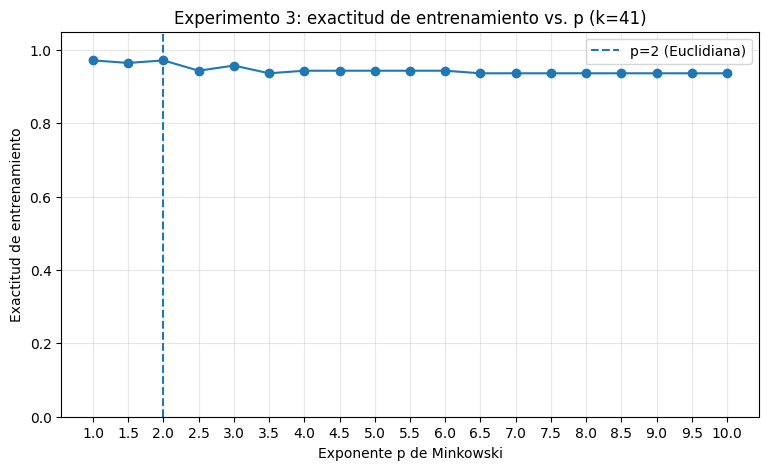

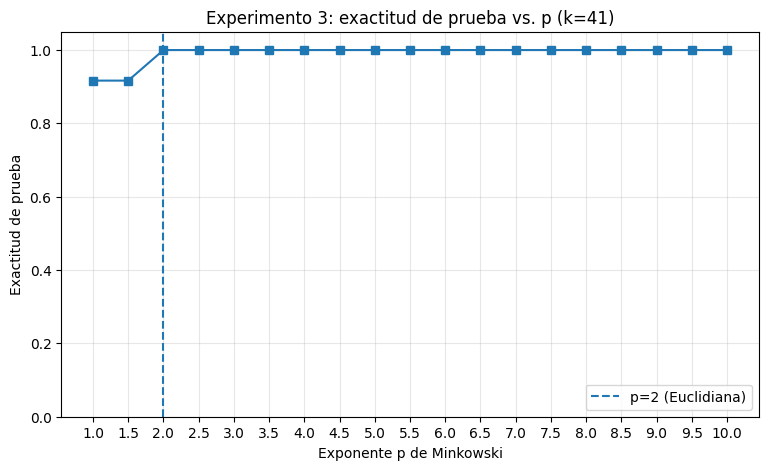

Resultado con p=2: exactitud de prueba = 1.000
Mejor resultado de prueba en la búsqueda: p=2.0, exactitud = 1.000
En esta partición, el mejor valor evaluado empata con p=2 en exactitud de prueba.


In [ ]:
p_values = np.arange(1.0, 10.0 + 0.001, 0.5)
resultados_p = []

for p in p_values:
    pred_train = knn_norm.predict(X_train_norm, k=k_optimo, p=float(p))
    pred_test = knn_norm.predict(X_test_norm, k=k_optimo, p=float(p))
    resultados_p.append({
        'p': float(p),
        'Exactitud entrenamiento': accuracy_score(y_train, pred_train),
        'Exactitud prueba': accuracy_score(y_test, pred_test)
    })

df_p = pd.DataFrame(resultados_p)
display(df_p.style.format({'p': '{:.1f}', 'Exactitud entrenamiento': '{:.3f}', 'Exactitud prueba': '{:.3f}'}))


# Gráfica solicitada para entrenamiento.
plt.figure(figsize=(9, 5))
plt.plot(df_p['p'], df_p['Exactitud entrenamiento'], marker='o')
plt.axvline(2, linestyle='--', label='p=2 (Euclidiana)')
plt.xlabel('Exponente p de Minkowski')
plt.ylabel('Exactitud de entrenamiento')
plt.title(f'Experimento 3: exactitud de entrenamiento vs. p (k={k_optimo})')
plt.xticks(p_values)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Gráfica solicitada para prueba.
plt.figure(figsize=(9, 5))
plt.plot(df_p['p'], df_p['Exactitud prueba'], marker='s')
plt.axvline(2, linestyle='--', label='p=2 (Euclidiana)')
plt.xlabel('Exponente p de Minkowski')
plt.ylabel('Exactitud de prueba')
plt.title(f'Experimento 3: exactitud de prueba vs. p (k={k_optimo})')
plt.xticks(p_values)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

fila_p2 = df_p.iloc[(df_p['p'] - 2).abs().argmin()]
fila_mejor_p = df_p.loc[df_p['Exactitud prueba'].idxmax()]
print(f"Resultado con p=2: exactitud de prueba = {fila_p2['Exactitud prueba']:.3f}")
print(f"Mejor resultado de prueba en la búsqueda: p={fila_mejor_p['p']:.1f}, exactitud = {fila_mejor_p['Exactitud prueba']:.3f}")
if fila_mejor_p['Exactitud prueba'] > fila_p2['Exactitud prueba']:
    print('En esta partición, al menos un valor evaluado de p supera la exactitud de p=2; verifica la diferencia en la gráfica.')
elif fila_mejor_p['Exactitud prueba'] == fila_p2['Exactitud prueba']:
    print('En esta partición, el mejor valor evaluado empata con p=2 en exactitud de prueba.')
else:
    print('En esta partición, p=2 logra una exactitud de prueba mayor que los demás valores evaluados.')


## Análisis del experimento 3: efecto del exponente p de Minkowski

En este experimento se utilizaron los datos normalizados con Z-score y se mantuvo fijo k = 41, seleccionado por su elevada exactitud de prueba en el experimento anterior. Se evaluaron 19 valores de p, desde 1 hasta 10, con incrementos de 0.5.

En el conjunto de prueba, con p = 1 (distancia Manhattan) y p = 1.5 se obtuvo una exactitud del 91.67 %. En cambio, con p = 2 (distancia euclidiana) se alcanzó el 100 %. Los valores evaluados entre p = 2.5 y p = 10 también obtuvieron una exactitud de prueba del 100 %.

En el conjunto de entrenamiento, las exactitudes fueron elevadas para todos los exponentes evaluados, aunque presentaron algunas variaciones. Con p = 2, la exactitud de entrenamiento fue del 97.18 %, mientras que para exponentes mayores se observaron valores cercanos al 94 % en varios puntos.

**¿Existe un valor de p que mejore consistentemente los resultados respecto a p = 2?**

En esta partición no se encontró un valor de p que superara la exactitud de prueba obtenida con p = 2. Varios exponentes mayores, desde p = 2.5 hasta p = 10, empataron con la distancia euclidiana al alcanzar el 100 %. Por tanto, p = 2 obtuvo uno de los mejores resultados, pero no fue el único que consiguió la exactitud máxima. Como solo se utilizó una partición del dataset, no se puede asegurar que estos resultados se mantengan con otras divisiones de los datos.

La distancia Manhattan suma las diferencias absolutas entre las características, mientras que la euclidiana calcula la raíz cuadrada de la suma de las diferencias al cuadrado. Al aumentar p, las diferencias de mayor magnitud adquieren más influencia en el cálculo de la distancia. Para valores muy grandes de p, esta distancia se aproxima a la de Chebyshev, que considera la máxima diferencia absoluta entre las características.

**Conclusión:** la elección de la métrica de distancia puede modificar las predicciones de KNN. En este experimento, p = 1 y p = 1.5 obtuvieron resultados inferiores en prueba, mientras que p = 2 y los exponentes mayores evaluados alcanzaron el 100 %. No se observó una mejora sobre p = 2 en exactitud de prueba, aunque varios exponentes empataron con él.

---

## 2.5. Preguntas de análisis

### 1. ¿Cómo afecta el número de vecinos k a la predicción final? Describe el comportamiento en los extremos.

El valor de k determina cuántos vecinos participan en la votación para clasificar una muestra. Con un k pequeño, la predicción depende de pocos ejemplos y puede ser más sensible a las características de los vecinos individuales. Con un k grande, la decisión considera un grupo más amplio de muestras y puede perder capacidad para distinguir entre las clases.

En los resultados obtenidos, con k = 1 la exactitud de entrenamiento fue del 100 %, mientras que la de prueba fue del 94.44 %. Esta diferencia es un indicio de que el resultado sobre entrenamiento es más favorable. Además, cada muestra de entrenamiento puede ser su propio vecino más cercano, lo que favorece artificialmente la exactitud de entrenamiento cuando k = 1.

En cambio, con k = 41 y k = 81 se alcanzó una exactitud de prueba del 100 %. Sin embargo, al aumentar k hasta 101, la exactitud disminuyó aproximadamente al 70 % en entrenamiento y al 77.78 % en prueba. Con k = 121, ambas exactitudes descendieron aproximadamente al 40 % y al 41.67 %, respectivamente.

Estos últimos resultados son consistentes con el subajuste: al considerar demasiados vecinos, el modelo realiza votaciones demasiado generales y pierde capacidad para separar correctamente las clases.

Las curvas se aproximan con valores grandes de k, especialmente con k = 121, pero lo hacen cuando la exactitud es baja. Por tanto, la proximidad entre las curvas no significa necesariamente que el modelo esté funcionando bien.

### 2. ¿La normalización de los datos influyó en el desempeño del modelo?

Sí. La normalización Z-score mejoró notablemente el desempeño de KNN en esta partición del dataset Wine.

En la comparación obtenida, la mejor exactitud de prueba sin normalizar fue del 80.56 %, mientras que con Z-score alcanzó el 100 %. La diferencia es de 19.44 puntos porcentuales.

Este resultado se explica por las diferencias de escala entre las características del dataset. Por ejemplo, Proline presenta valores del orden de cientos a más de mil, mientras que Hue tiene valores cercanos a 0.5–1.7. Si los datos no se normalizan, las características con diferencias numéricas más grandes pueden dominar el cálculo de la distancia euclidiana.

La normalización Z-score transforma cada característica utilizando la media y la desviación estándar del conjunto de entrenamiento, y aplica esa misma transformación al conjunto de prueba. Así, las características quedan en escalas comparables y sus diferencias influyen de forma más equilibrada en la selección de los vecinos.

**Conclusión:** la normalización tuvo un efecto positivo en el desempeño observado. Sin embargo, no elimina el subajuste causado por utilizar demasiados vecinos, como se observa cuando k aumenta hasta 101 y 121.

### 3. ¿Cómo influyó el valor de p en la calidad de los resultados? ¿Hubo algún valor notablemente distinto? ¿Qué concluyes sobre la importancia de elegir la métrica de distancia adecuada?

El exponente p modifica la forma en que KNN calcula la distancia entre las muestras y, por tanto, puede cambiar qué vecinos se seleccionan para la votación.

En el conjunto de prueba, p = 1 y p = 1.5 obtuvieron una exactitud del 91.67 %, mientras que p = 2 y los valores evaluados entre 2.5 y 10 alcanzaron el 100 %. Por ello, los resultados más bajos se observaron con los exponentes 1 y 1.5; los exponentes iguales o superiores a 2 consiguieron la máxima exactitud de prueba en esta partición.

En entrenamiento, las diferencias entre exponentes fueron menores, ya que las exactitudes se mantuvieron aproximadamente entre el 94 % y el 97 %. Esto demuestra que una métrica puede producir cambios en las predicciones de entrenamiento sin que necesariamente mejore el resultado sobre muestras nuevas.

Se concluye que elegir una métrica de distancia adecuada es importante porque determina qué muestras se consideran más próximas. En este experimento, p = 2 fue una buena elección, aunque no superó a todos los exponentes restantes en exactitud de prueba, dado que varios obtuvieron el mismo 100 %. Para determinar qué métrica generaliza mejor de manera consistente, sería conveniente repetir la evaluación con diferentes particiones o utilizar validación cruzada.
